# Capital contable y estabilidad de depósitos: exploración temporal

## Pregunta y límites
¿Existe una asociación descriptiva entre el nivel contable de patrimonio y los cambios de depósitos posteriores, o entre los cambios de depósitos y la variación posterior del cociente de patrimonio? Los datos FDIC permiten estudiar una sola entidad y dos indicadores trimestrales. **Depósitos no son un indicador completo de liquidez** y patrimonio/activos no equivale a capital regulatorio. Esta exploración no identifica retroalimentación causal ni evidencia de contagio.

## Fuente y método

Fuente: [FDIC BankFind API](https://api.fdic.gov/banks/docs/), institución JPMorgan Chase Bank, N.A. (CERT 628), corte público descargado 2026-11-12. Extracto congelado JSON, 50 trimestres más recientes hasta 2026-06-30; montos en miles USD. `ASSET` activos, `LIAB` pasivos, `EQ` patrimonio, `DEP` depósitos, `LNLSNET` préstamos netos y `SC` valores. [FDIC Financial Reporting](https://banks.data.fdic.gov/bankfind-suite/financialreporting/report) ofrece datos trimestrales. El archivo y su huella se guardan junto al notebook de balance estocástico.

Para evitar coincidencia mecánica en el mismo trimestre se alinean variables con un rezago trimestral. Las asociaciones son sensibles a fusiones, cambios de negocio, nivel de tasas y régimen. No se imputan observaciones ni se extrapola la muestra a otros bancos.

In [1]:
from pathlib import Path
import json,hashlib,numpy as np,pandas as pd,matplotlib.pyplot as plt
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'03-financial-risk').is_dir())
p=root/'03-financial-risk/05-enterprise-risk-advisory/02-capital-alm/stochastic-balance-sheet-alm/data/fdic_cert628_2026-11-12.json'
raw=json.loads(p.read_text());df=pd.DataFrame([item['data'] for item in raw['data']]);df['fecha']=pd.to_datetime(df.REPDTE,format='%Y%m%d');df=df.sort_values('fecha').reset_index(drop=True)
for c in ['ASSET','LIAB','EQ','DEP','LNLSNET','SC']:df[c]=pd.to_numeric(df[c],errors='coerce')
assert len(df)==50 and not df.fecha.duplicated().any() and df[['ASSET','LIAB','EQ','DEP']].notna().all().all()
assert (df[['ASSET','LIAB','DEP']]>0).all().all()
print('SHA-256:',hashlib.sha256(p.read_bytes()).hexdigest(),'| periodos:',len(df),'| corte:',df.fecha.min().date(),df.fecha.max().date())
print('Índice de origen:',raw['meta']['index']['name']); print('Máx. diferencia activos − pasivos − patrimonio (miles USD):', (df.ASSET-df.LIAB-df.EQ).abs().max())
df['ratio_capital']=df.EQ/df.ASSET;df['ratio_depositos']=df.DEP/df.ASSET

SHA-256: 307771a9e02673a881ad7b4112de81ea9cb2f69c8db3e954df9beffe0036a337 | periodos: 50 | corte: 2014-03-31 2026-06-30
Índice de origen: risview_20260819185831
Máx. diferencia activos − pasivos − patrimonio (miles USD): 266000


## Construcción y controles
Dos pares predefinidos: 1) patrimonio/activos al cierre anterior frente al crecimiento de depósitos del trimestre siguiente; 2) crecimiento de depósitos del trimestre anterior frente a la variación en puntos porcentuales del cociente de patrimonio. Las observaciones solo se usan si los trimestres son consecutivos. Las cifras de activos menos pasivos y patrimonio reportado presentan una diferencia residual; no se ha atribuido a ningún componente contable.

In [2]:
assert df.fecha.dt.to_period('Q').diff().dropna().map(lambda x:x.n==1).all()
df['crec_deposito']=df.DEP.pct_change(fill_method=None)
df['cambio_capital_pp']=100*df.ratio_capital.diff()
df['capital_rezagado_pct']=100*df.ratio_capital.shift(1)
df['deposito_rezagado_pct']=100*df.crec_deposito.shift(1)
df['crec_deposito_pct']=100*df.crec_deposito
cols=['capital_rezagado_pct','crec_deposito_pct','deposito_rezagado_pct','cambio_capital_pp'];a=df.dropna(subset=cols).copy(); print('Pares trimestrales:',len(a),'|',a.fecha.min().date(),a.fecha.max().date());a[['fecha']+cols].tail()

Pares trimestrales: 48 | 2014-09-30 2026-06-30


,fecha,capital_rezagado_pct,crec_deposito_pct,deposito_rezagado_pct,cambio_capital_pp
45,2025-06-30,8.690760,2.611850,3.346169,-0.170959
46,2025-09-30,8.519801,-0.738921,2.611850,0.185037
47,2025-12-31,8.704838,1.826953,-0.738921,0.247100
48,2026-03-31,8.951939,3.341634,1.826953,-0.588312
49,2026-06-30,8.363627,1.158180,3.341634,-0.014722


## Asociación, sensibilidad temporal y tamaño muestral
Pearson mide asociación lineal y Spearman orden; se presentan para la muestra completa y dos subperiodos definidos previamente. Son descriptivos, sin prueba de hipótesis causal ni intervalos que ignoren dependencia serial.

In [3]:
pairs=[('Capital previo → depósitos','capital_rezagado_pct','crec_deposito_pct'),('Depósitos previos → capital','deposito_rezagado_pct','cambio_capital_pp')]
rows=[]
for label,x,y in pairs:
 for name,group in [('Total',a),('2014–2019',a[a.fecha<'2020-01-01']),('2020–2026',a[a.fecha>='2020-01-01'])]:
    rows.append({'par':label,'periodo':name,'N':len(group),'pearson':group[x].corr(group[y]),'spearman':group[x].corr(group[y],method='spearman')})
pd.DataFrame(rows).round(3)

,par,periodo,N,pearson,spearman
0,Capital previo → depósitos,Total,48,0.255,0.147
1,Capital previo → depósitos,2014–2019,22,0.309,0.342
2,Capital previo → depósitos,2020–2026,26,0.644,0.444
3,Depósitos previos → capital,Total,48,-0.050,-0.042
4,Depósitos previos → capital,2014–2019,22,-0.050,0.002
5,Depósitos previos → capital,2020–2026,26,0.007,-0.080


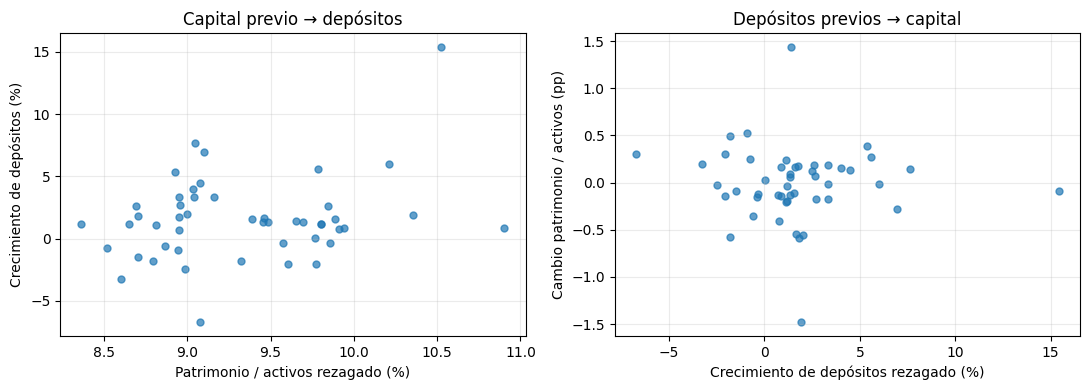

In [4]:
fig,ax=plt.subplots(1,2,figsize=(11,4));
for axis,(label,x,y) in zip(ax,pairs):
    axis.scatter(a[x],a[y],s=25,alpha=.7);axis.set_title(label);axis.grid(alpha=.25)
ax[0].set(xlabel='Patrimonio / activos rezagado (%)',ylabel='Crecimiento de depósitos (%)');ax[1].set(xlabel='Crecimiento de depósitos rezagado (%)',ylabel='Cambio patrimonio / activos (pp)');plt.tight_layout();plt.show()

## Qué puede decidirse
El análisis permite formular preguntas de vigilancia y contrastar sensibilidad de la asociación por periodo. Para medir retroalimentación hacen falta flujos y vencimientos, liquidez disponible, tasas de fondeo, capital regulatorio, exposiciones, decisiones de gestión y un diseño que contemple efectos comunes y causalidad inversa. Los registros de un banco no permiten atribuir los cambios a una política ni estimar pérdidas de liquidez.